CNN Classifier

In [24]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader, random_split
from sklearn.metrics import classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


Device Configuration

In [25]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


Using device: cuda


Dataset Loading and Preprocessing

In [26]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training dataset:", len(train_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 50000
Testing dataset: 10000


Training and Validation Split

In [27]:
torch.manual_seed(42)

train_subset, validation_subset = random_split(
    train_dataset,
    [45000, 5000]
)

print("Training images:", len(train_subset))
print("Validation images:", len(validation_subset))
print("Testing images:", len(test_dataset))

Training images: 45000
Validation images: 5000
Testing images: 10000


Creating DataLoaders

In [28]:
batch_size = 128

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)

validation_loader = DataLoader(
    validation_subset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


Define the CNN Architecture

In [29]:
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))

        x = self.pool(self.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = self.fc(x)

        return x


model = CNN().to(device)

print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)


Counting Trainable Parameters

In [30]:
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total trainable parameters:", total_parameters)

Total trainable parameters: 60362


Configuring Loss Function and Optimizer

In [31]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function and optimizer configured successfully!")

Loss function and optimizer configured successfully!


Training the CNN Model

In [32]:
num_epochs = 10

train_losses = []
validation_losses = []
validation_accuracies = []

print("Training settings configured!")

Training settings configured!


Setting Training Parameters

In [33]:
num_epochs = 10

train_losses = []
validation_losses = []
train_accuracies = []
validation_accuracies = []

for epoch in range(num_epochs):

    # Training
    model.train()
    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_train_loss / train_total
    train_accuracy = 100 * train_correct / train_total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Validation
    model.eval()
    running_validation_loss = 0.0
    validation_correct = 0
    validation_total = 0

    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_validation_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            validation_correct += (predictions == labels).sum().item()
            validation_total += labels.size(0)

    validation_loss = running_validation_loss / validation_total
    validation_accuracy = 100 * validation_correct / validation_total

    validation_losses.append(validation_loss)
    validation_accuracies.append(validation_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Training Loss: {train_loss:.4f} "
        f"Training Accuracy: {train_accuracy:.2f}% "
        f"Validation Loss: {validation_loss:.4f} "
        f"Validation Accuracy: {validation_accuracy:.2f}%"
    )

Epoch [1/10] Training Loss: 1.3947 Training Accuracy: 50.64% Validation Loss: 1.1591 Validation Accuracy: 59.30%
Epoch [2/10] Training Loss: 1.0434 Training Accuracy: 63.93% Validation Loss: 1.0031 Validation Accuracy: 65.14%
Epoch [3/10] Training Loss: 0.9112 Training Accuracy: 68.73% Validation Loss: 0.9275 Validation Accuracy: 67.90%
Epoch [4/10] Training Loss: 0.8287 Training Accuracy: 71.72% Validation Loss: 0.9293 Validation Accuracy: 68.02%
Epoch [5/10] Training Loss: 0.7686 Training Accuracy: 73.64% Validation Loss: 0.8710 Validation Accuracy: 70.00%
Epoch [6/10] Training Loss: 0.7127 Training Accuracy: 75.61% Validation Loss: 0.8723 Validation Accuracy: 70.06%
Epoch [7/10] Training Loss: 0.6627 Training Accuracy: 77.48% Validation Loss: 0.8520 Validation Accuracy: 70.78%
Epoch [8/10] Training Loss: 0.6216 Training Accuracy: 78.75% Validation Loss: 0.8531 Validation Accuracy: 71.06%
Epoch [9/10] Training Loss: 0.5806 Training Accuracy: 80.21% Validation Loss: 0.8982 Validation 

Visualising Training and Validation Loss

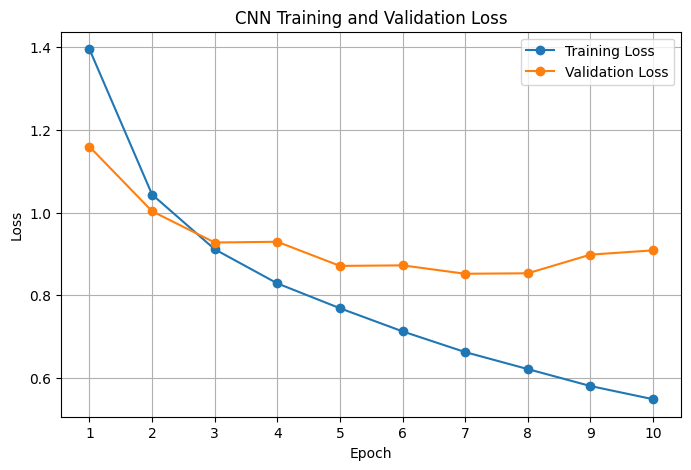

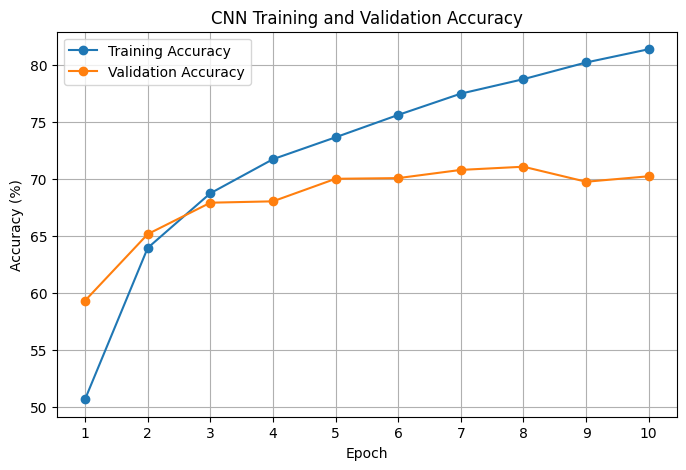

In [34]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, validation_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(epochs, validation_accuracies, marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Training and Validation Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

Evaluating the CNN Model on Test Data

In [35]:
model.eval()

correct = 0
total = 0
test_loss = 0.0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)
        test_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total
test_loss = test_loss / len(test_loader)

print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 70.01%
Test Loss: 0.9249


Classification Report

In [36]:
from sklearn.metrics import classification_report

all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
))

              precision    recall  f1-score   support

    airplane       0.73      0.73      0.73      1000
  automobile       0.89      0.71      0.79      1000
        bird       0.70      0.45      0.55      1000
         cat       0.53      0.56      0.55      1000
        deer       0.56      0.77      0.65      1000
         dog       0.73      0.48      0.58      1000
        frog       0.70      0.85      0.77      1000
       horse       0.74      0.77      0.76      1000
        ship       0.82      0.82      0.82      1000
       truck       0.70      0.86      0.77      1000

    accuracy                           0.70     10000
   macro avg       0.71      0.70      0.70     10000
weighted avg       0.71      0.70      0.70     10000



Verifying the Total Trainable Parameters

In [37]:
total_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total trainable parameters:", total_parameters)

Total trainable parameters: 60362


Saving the Trained CNN Model

In [38]:
torch.save(model.state_dict(), "cnn_model.pth")

print("CNN model saved successfully!")

CNN model saved successfully!


MLP & CNN Comparision

In [39]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "MLP",
        "Training Accuracy (%)": 76.21,  # MLP training accuracy from Exercise 1
        "Test Accuracy (%)": 53.25,
        "Training Loss": 0.8002,
        "Validation Loss": 1.5685,
        "Test Loss": 1.5648,
        "Trainable Parameters": 1_707_274,
    },
    {
        "Model": "CNN",
        "Training Accuracy (%)": 81.19,  # CNN training accuracy from Exercise 2
        "Test Accuracy (%)": test_accuracy,
        "Training Loss": train_losses[-1],
        "Validation Loss": validation_losses[-1],
        "Test Loss": test_loss,
        "Trainable Parameters": sum(
            p.numel() for p in model.parameters() if p.requires_grad
        ),
    },
])

comparison

,Model,Training Accuracy (%),Test Accuracy (%),Training Loss,Validation Loss,Test Loss,Trainable Parameters
0,MLP,76.21,53.25,0.800200,1.568500,1.564800,1707274
1,CNN,81.19,70.01,0.548773,0.908582,0.924942,60362
